<a href="https://colab.research.google.com/github/mashadiyevasabina/Cohort-Analysis-Customer-Retention-Purchase-Behavior/blob/main/Cohort_Analysis_jpynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#📜 Kohort Analizi Hesabatı: Müştəri Saxlama (Retention) və Davranış Analizi


##2. İstifadə Olunan Cədvəllər və Göstəricilər (Dataset Structure)
Analiz zamanı əsasən sales (Satışlar) cədvəlindən istifadə olunmuş və aşağıdakı sütunlar üzərində hesablama aparılmışdır:

order_id — Sifarişin unikal identifikasiya nömrəsi.

order_date — Sifarişin verildiyi dəqiq tarix.

status — Sifarişin statusu (Tamamlandı, Ləğv edildi, Qaytarıldı və s.).

item_id / sku — Sifariş edilən məhsulun unikal kodu.

qty_ordered — Sifariş edilən məhsulun sayı.

price — Məhsulun vahid qiyməti.

discount_amount — Tətbiq olunan endirim məbləği.

payment_method — Ödəniş üsulu (Kredit kartı, Nağd və s.).

bi_st / ref_num — Sifarişin sistem daxili sorğu və hesabat referans nömrələri.

year / month — Sifarişin ili və ayı (Zaman oxu üzrə qruplaşdırma üçün).

category — Məhsulun daxil olduğu kateqoriya

cust_id — Müştərinin unikal nömrəsi (Kohort analizinin əsas açar sütunu).

Name Prefix, First Name, Middle Initial, Last Name, full_name —Müştərinin ad, soyad və müraciət məlumatları.

Gender — Müştərinin cinsi.

age — Müştərinin yaşı.

E Mail, Customer Since, SSN, Phone No., User Name — Əlaqə, qeydiyyat və profil məlumatları.

Place Name, County, City, State, Zip, Region — Sifarişin çatdırıldığı coğrafi ərazi (şəhər, ştat, region, poçt kodu).

# 3. Əsas KPI-lar (Key Performance Indicators)

**İlkin Kohort Ölçüsü (Base Cohort Size):** Hər ay platformaya daxil olan yeni unikal müştərilərin sayı.

**Retention Rate (%):** Müştərilərin ilk alış-verişdən sonra növbəti aylarda geri qayıtma faizi ($Retention = \frac{\text{Aktiv Müştəri Sayı}}{\text{İlk Aydakı Müştəri Sayı}} \times 100$).

**Churn Rate (%):** Məhsulu və ya xidməti tərk edən müştərilərin nisbəti ($Churn = 100\% - Retention\%$).

**Müştəri Ömrü / Aktivlik Dövrü (Customer Lifetime / Retention Curve)**: Müştəri qruplarının zaman keçdikcə platformada qalma davamlılığı.

**Təkrar Sifariş Tezliyi (Repeat Purchase Rate):** Bir müştərinin müəyyən dövr ərzində birdən çox sifariş vermə sıxlığı.

## 1. Data Overview və Data Cleaning

### Task 1. Data Overview

Lazım olan kitabxanaları import edin, `sales.csv` faylını yükləyin və datasetlə ümumi tanışlıq aparaq.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir('/content/drive/MyDrive/cohort analysis 1 student')
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#sales = pd.read_csv("/content/drive/MyDrive/cohort analysis 1 student/sales.csv", encoding="latin-1")

In [ ]:
sales = pd.read_csv("/content/drive/MyDrive/cohort analysis 1 student/sales.csv", encoding="latin-1", low_memory=False)

In [ ]:
# Sales cədvəlinə baxış keirək
sales

,order_id,order_date,status,item_id,sku,qty_ordered,price,discount_amount,category,payment_method,...,Customer Since,SSN,Phone No.,Place Name,County,City,State,Zip,Region,User Name
0,100354678,01-10-2020,received,574772,oasis_Oasis-064-36,21,89.9,0.0,Men's Fashion,cod,...,8/22/2006,627-31-5251,405-959-1129,Vinson,Harmon,Vinson,OK,73571,South,jwtitus
1,100354678,01-10-2020,received,574774,Fantastic_FT-48,11,19.0,0.0,Men's Fashion,cod,...,8/22/2006,627-31-5251,405-959-1129,Vinson,Harmon,Vinson,OK,73571,South,jwtitus
2,100354680,01-10-2020,complete,574777,mdeal_DMC-610-8,9,149.9,0.0,Men's Fashion,cod,...,8/22/2006,627-31-5251,405-959-1129,Vinson,Harmon,Vinson,OK,73571,South,jwtitus
3,100354680,01-10-2020,complete,574779,oasis_Oasis-061-36,9,79.9,0.0,Men's Fashion,cod,...,8/22/2006,627-31-5251,405-959-1129,Vinson,Harmon,Vinson,OK,73571,South,jwtitus
4,100367357,13-11-2020,received,595185,MEFNAR59C38B6CA08CD,2,99.9,0.0,Men's Fashion,cod,...,8/22/2006,627-31-5251,405-959-1129,Vinson,Harmon,Vinson,OK,73571,South,jwtitus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286387,100562365,30-09-2021,paid,905179,APPCHA5AF14939B8F8A,2,4419.9,0.0,Appliances,Easypay,...,3/21/2007,613-87-0361,212-772-7404,Rushville,Yates,Rushville,NY,14544,Northeast,bklatham
286388,100562376,30-09-2021,cod,905191,MEFCOT5A8D1E973B886,2,39.9,0.0,Men's Fashion,cod,...,10/24/2011,101-02-1040,229-817-9451,Lawrenceville,Gwinnett,Lawrenceville,GA,30044,South,bmbrunetti
286389,100562383,30-09-2021,cod,905200,WOFVAL59D5EA84167F9-M,2,40.0,0.0,Women's Fashion,cod,...,7/25/1987,399-31-7238,252-414-8396,Durham,Durham,Durham,NC,27701,South,fngiusti
286390,100562384,30-09-2021,cod,905202,WOFNIG5B4D7EB0E9FDD-L,2,49.9,0.0,Women's Fashion,cod,...,7/25/1987,399-31-7238,252-414-8396,Durham,Durham,Durham,NC,27701,South,fngiusti


In [ ]:
sales.shape

(286392, 33)

In [ ]:
# Sales cedveli haqqinda informasiya elde edek
sales.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286392 entries, 0 to 286391
Data columns (total 33 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         286392 non-null  object 
 1   order_date       286392 non-null  object 
 2   status           286392 non-null  object 
 3   item_id          286392 non-null  int64  
 4   sku              286392 non-null  object 
 5   qty_ordered      286392 non-null  int64  
 6   price            286392 non-null  float64
 7   discount_amount  286392 non-null  float64
 8   category         286392 non-null  object 
 9   payment_method   286392 non-null  object 
 10  bi_st            286392 non-null  object 
 11  cust_id          286392 non-null  int64  
 12  year             286392 non-null  int64  
 13  month            286392 non-null  object 
 14  ref_num          286392 non-null  int64  
 15  Name Prefix      286392 non-null  object 
 16  First Name       286392 non-null  obje

#Task 2. Data Cleaning

Cohort analysis üçün lazım olan sütunları saxlayaq və datada ümumi cleaning işləri aparaq. Missing value və duplicate sətirləri birlikdə yoxlayaq,



In [ ]:
# Biz bu 33 swtundan cohort analizinde bize lazim olacaq swtunlari secek ve yeni bir cedvel kimi bundan sonraki analizlerde hemin cedvel uzerinden davam edek hemcinin bize tamamlanmis sifarislerden ibaret cedvel lazimdir
complated_orders=sales[sales['status']=='complete']
complated_orders
 #swtunlari secek
sales=complated_orders[['cust_id', 'order_date', 'order_id', 'qty_ordered', 'price','discount_amount']].copy()
sales

,cust_id,order_date,order_id,qty_ordered,price,discount_amount
2,60124,01-10-2020,100354680,9,149.9,0.00
3,60124,01-10-2020,100354680,9,79.9,0.00
24,42485,24-12-2020,100403536,3,254.8,101.92
25,42485,24-12-2020,100403536,3,315.5,126.20
26,42485,24-12-2020,100403536,3,69.8,27.92
...,...,...,...,...,...,...
281773,113791,02-09-2021,100554480,2,29.0,0.00
281774,113791,02-09-2021,100554480,2,34.9,0.00
281775,113791,02-09-2021,100554480,3,9.0,0.00
281776,113791,02-09-2021,100554480,2,9.0,0.00


In [ ]:
sales.shape

(88968, 6)

In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
Index: 88968 entries, 2 to 281777
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cust_id          88968 non-null  int64  
 1   order_date       88968 non-null  object 
 2   order_id         88968 non-null  object 
 3   qty_ordered      88968 non-null  int64  
 4   price            88968 non-null  float64
 5   discount_amount  88968 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 4.8+ MB


In [ ]:
# Order_date sutunnunu tipini datetime edek
sales['order_date']=pd.to_datetime(sales['order_date'], format="%d-%m-%Y")
sales['order_id']=sales['order_id'].astype(int)
sales.info()

<class 'pandas.core.frame.DataFrame'>
Index: 88968 entries, 2 to 281777
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   cust_id          88968 non-null  int64         
 1   order_date       88968 non-null  datetime64[ns]
 2   order_id         88968 non-null  int64         
 3   qty_ordered      88968 non-null  int64         
 4   price            88968 non-null  float64       
 5   discount_amount  88968 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(3)
memory usage: 4.8 MB


In [ ]:
sales.isna().sum()

,0
cust_id,0
order_date,0
order_id,0
qty_ordered,0
price,0
discount_amount,0


misising valueler yoxdur

In [ ]:
sales.duplicated().sum()

np.int64(3233)

In [ ]:
#3233 dublikat sətri temizleyek
sales=sales.drop_duplicates()
sales.shape

(85735, 6)

### Task 3. Revenue

Hər sifariş sətri üçün `revenue` dəyişəni yaradaq

> **Tip:** Hesablamada `qty_ordered`, `price` və `discount_amount` sütunlarından istifadə edək.

In [ ]:
sales["revenue"]=sales["price"]*sales["qty_ordered"]-sales['discount_amount']
sales.head()

/tmp/ipykernel_2328/1747555589.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,cust_id,order_date,order_id,qty_ordered,price,discount_amount,revenue
2,60124,2020-10-01,100354680,9,149.9,0.00,1349.10
3,60124,2020-10-01,100354680,9,79.9,0.00,719.10
24,42485,2020-12-24,100403536,3,254.8,101.92,662.48
25,42485,2020-12-24,100403536,3,315.5,126.20,820.30
26,42485,2020-12-24,100403536,3,69.8,27.92,181.48


In [ ]:
sales=sales.drop(columns=['qty_ordered','price','discount_amount'])
sales.head()

,cust_id,order_date,order_id,revenue
2,60124,2020-10-01,100354680,1349.10
3,60124,2020-10-01,100354680,719.10
24,42485,2020-12-24,100403536,662.48
25,42485,2020-12-24,100403536,820.30
26,42485,2020-12-24,100403536,181.48


## 2. Aylıq cohort analysis

### Task 4. First order date

Hər customer-in ilk sifariş tarixini hesablayaq və bu məlumatı əsas `orders` dataframe-inə əlavə edek

In [ ]:
#sales['first_order_date']=
first_order_date=sales.groupby('cust_id')['order_date'].min()



In [ ]:
# order_date sutununun adini deyisek
first_order_date.name='first_order'


In [ ]:
# Indi bu cedveli cust_id swtunu vasitesile sales cedveline birlesdirek
orders=sales.join(first_order_date, on='cust_id')
orders


,cust_id,order_date,order_id,revenue,first_order
2,60124,2020-10-01,100354680,1349.10,2020-10-01
3,60124,2020-10-01,100354680,719.10,2020-10-01
24,42485,2020-12-24,100403536,662.48,2020-12-24
25,42485,2020-12-24,100403536,820.30,2020-12-24
26,42485,2020-12-24,100403536,181.48,2020-12-24
...,...,...,...,...,...
281773,113791,2021-09-02,100554480,58.00,2021-09-02
281774,113791,2021-09-02,100554480,69.80,2021-09-02
281775,113791,2021-09-02,100554480,27.00,2021-09-02
281776,113791,2021-09-02,100554480,18.00,2021-09-02


### Task 5. Aylıq period-lar

Customer-in ilk sifariş ayını və hər sifarişin baş verdiyi ayı göstərən dəyişənlər yaradaq. Datasetdə neçə fərqli aylıq cohort olduğunu müəyyən edek.



In [ ]:
orders['first_order_month'] = orders['first_order'].dt.to_period('M')
orders['order_month'] = orders['order_date'].dt.to_period('M')
orders

,cust_id,order_date,order_id,revenue,first_order,first_order_month,order_month
2,60124,2020-10-01,100354680,1349.10,2020-10-01,2020-10,2020-10
3,60124,2020-10-01,100354680,719.10,2020-10-01,2020-10,2020-10
24,42485,2020-12-24,100403536,662.48,2020-12-24,2020-12,2020-12
25,42485,2020-12-24,100403536,820.30,2020-12-24,2020-12,2020-12
26,42485,2020-12-24,100403536,181.48,2020-12-24,2020-12,2020-12
...,...,...,...,...,...,...,...
281773,113791,2021-09-02,100554480,58.00,2021-09-02,2021-09,2021-09
281774,113791,2021-09-02,100554480,69.80,2021-09-02,2021-09,2021-09
281775,113791,2021-09-02,100554480,27.00,2021-09-02,2021-09,2021-09
281776,113791,2021-09-02,100554480,18.00,2021-09-02,2021-09,2021-09


In [ ]:
orders["first_order_month"].nunique()

12

### Task 6. Cohort summary

Hər aylıq cohort üzrə unique order, unique customer və total revenue göstəricilərini hesablayın. Nəticəni tarix ardıcıllığı ilə təqdim edin.

In [ ]:
cohort_table = orders.groupby('first_order_month').agg({'order_id': 'nunique', 'cust_id': 'nunique', 'revenue': 'sum'})
cohort_table
cohort_table=cohort_table.rename(columns={'cust_id': 'unique_customer', 'order_id':'unique_order'}).reset_index()
cohort_table.head()

,first_order_month,unique_order,unique_customer,revenue
0,2020-10,5273,1444,8.624568e+06
1,2020-11,6584,2321,1.125041e+07
2,2020-12,30807,13184,6.808640e+07
3,2021-01,3542,2273,3.098298e+06
4,2021-02,2414,1342,1.876805e+06


### Task 7. Cohort summary visualization

Aylıq cohort-lar üzrə order, customer və revenue göstəricilərini uyğun qrafiklərlə vizuallaşdıraq və əsas müşahidələrinizi yazaq.

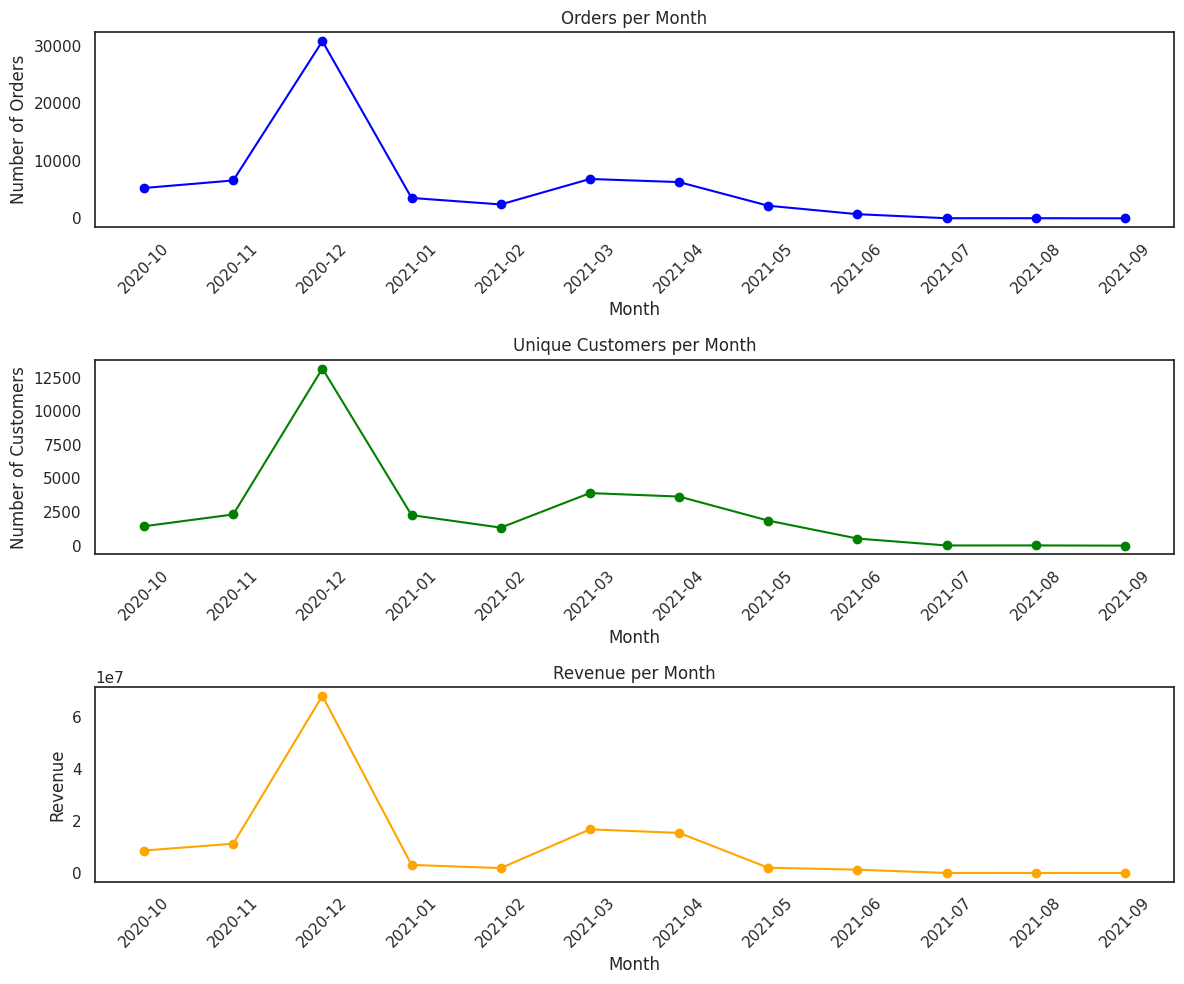

In [ ]:
cohort_table['first_order_month'] = cohort_table['first_order_month'].astype(str)
plt.figure(figsize=(12, 10))

# Plot 1: Orders
plt.subplot(3, 1, 1)
plt.plot(cohort_table['first_order_month'], cohort_table['unique_order'], marker='o', color='blue')
plt.title('Orders per Month')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

# Plot 2: Customers
plt.subplot(3, 1, 2)
plt.plot(cohort_table['first_order_month'], cohort_table['unique_customer'], marker='o', color='green')
plt.title('Unique Customers per Month')
plt.xlabel('Month')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

# Plot 3: Revenue
plt.subplot(3, 1, 3)
plt.plot(cohort_table['first_order_month'], cohort_table['revenue'], marker='o', color='orange')
plt.title('Revenue per Month')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

# Adjust layout and display
plt.tight_layout()
plt.show()

In [ ]:
# ən son sifariş tarixini araşdıraq
orders['order_date'].max()

Timestamp('2021-09-14 00:00:00')

demeli qrafiklerden aydin olur ki en yuksek satis, yeni musteri axını, sifaris saylarındakı pik hədd 2020 ci ilin dekabr ayında bas vermisdir. Daha sonra 2021 mart ayinda Bir qədər artım baş verib.  Bu bayramların və kompaniyalarin,  təsiri ola bilər.

### Task 8. Customer activity pivot table

Hər ay biznesə neçə təmiz yeni müştərinin daxil olduğuna baxaq

In [ ]:
#Sətirlərdə customer-in ilk sifariş ayı, sütunlarda isə sifariş ayı olacaq şəkildə unique customer saylarını göstərən pivot table yaradın. Nəticəni şərh edin.
orders.pivot_table(index='first_order_month', columns='order_month', values='cust_id', aggfunc='nunique')

order_month,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09
first_order_month,,,,,,,,,,,,
2020-10,1444.0,197.0,278.0,126.0,85.0,132.0,109.0,62.0,24.0,NaN,1.0,NaN
2020-11,NaN,2321.0,483.0,194.0,126.0,192.0,152.0,96.0,37.0,1.0,NaN,2.0
2020-12,NaN,NaN,13184.0,848.0,398.0,587.0,581.0,277.0,119.0,2.0,4.0,2.0
2021-01,NaN,NaN,NaN,2273.0,141.0,109.0,94.0,61.0,15.0,1.0,NaN,NaN
2021-02,NaN,NaN,NaN,NaN,1342.0,106.0,82.0,45.0,10.0,1.0,2.0,1.0
2021-03,NaN,NaN,NaN,NaN,NaN,3913.0,379.0,94.0,48.0,NaN,NaN,NaN
2021-04,NaN,NaN,NaN,NaN,NaN,NaN,3654.0,135.0,63.0,NaN,2.0,NaN
2021-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1864.0,31.0,NaN,NaN,NaN
2021-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,529.0,2.0,NaN,NaN


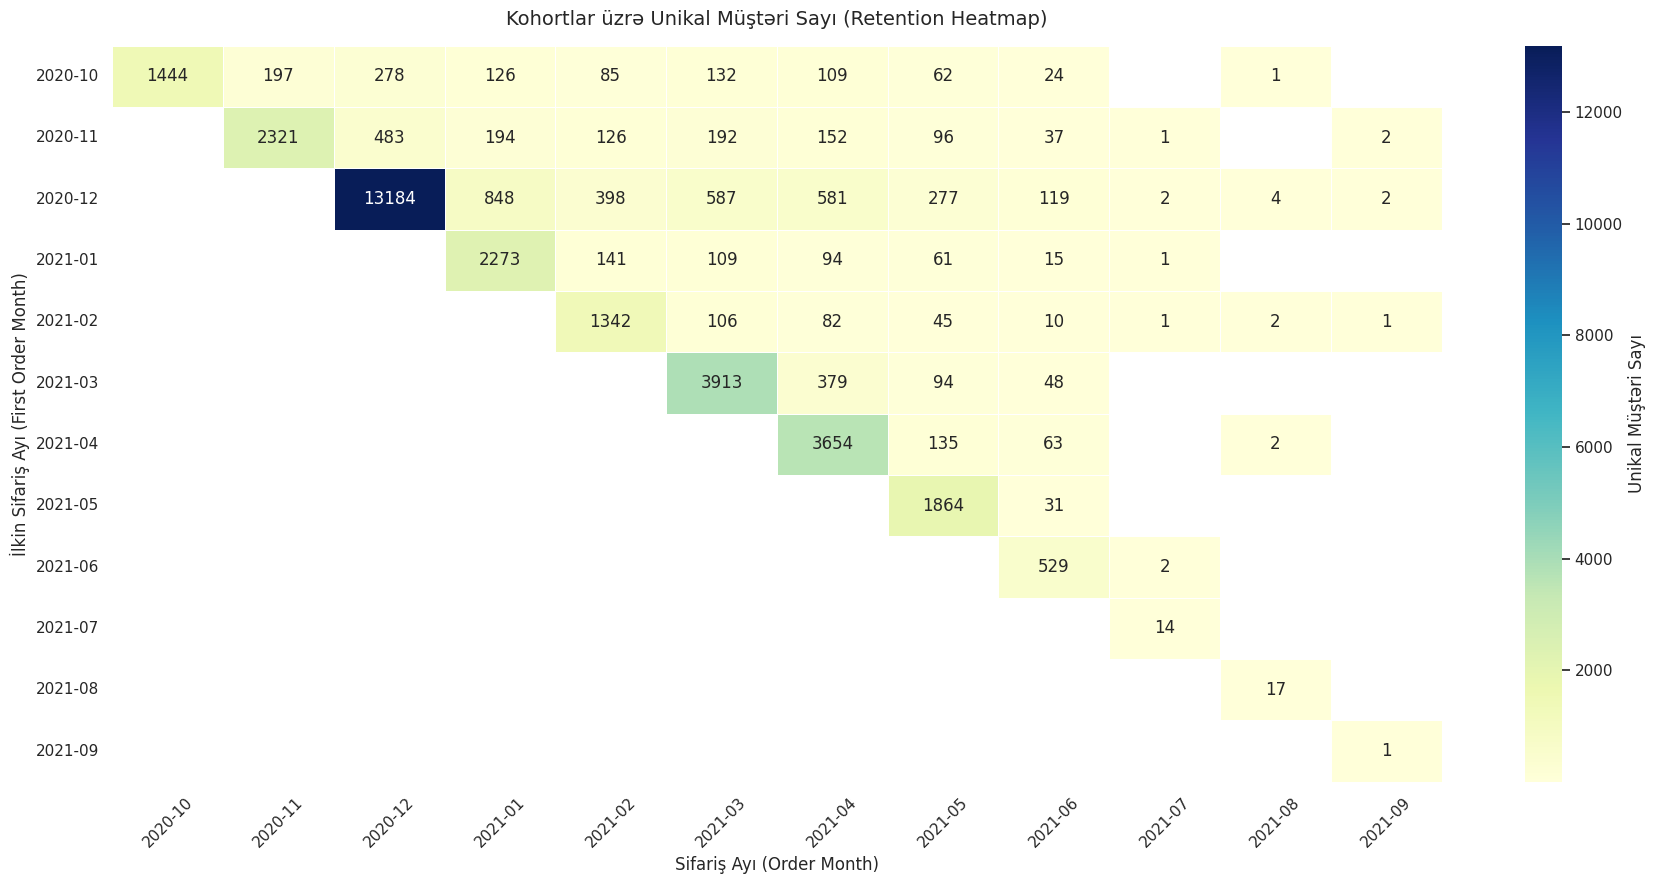

In [ ]:
# Pivot cədvəli dəyişənə mənimsəyirik
pivot_customers = orders.pivot_table(
    index="first_order_month",
    columns="order_month",
    values="cust_id",
    aggfunc="nunique",
)

# Heatmap qrafiki
plt.figure(figsize=(18, 9))
sns.heatmap(
    pivot_customers,
    annot=True,  # Xanadakı müştəri saylarını göstərmək üçün
    fmt=".0f",  # Tam ədədlər kimi formatlayırıq (tam müştəri sayı)
    cmap="YlGnBu",  # Rəng palitrası
    linewidths=0.5,
    cbar_kws={"label": "Unikal Müştəri Sayı"},
)

plt.title("Kohortlar üzrə Unikal Müştəri Sayı (Retention Heatmap)", fontsize=14, pad=15)
plt.xlabel("Sifariş Ayı (Order Month)", fontsize=12)
plt.ylabel("İlkin Sifariş Ayı (First Order Month)", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

"Biznes kəskin mövsümi xarakter daşıyır. 2020-ci ilin dekabrında pik nöqtəyə çatan satışlar və müştəri aktivliyi növbəti aylarda kəskin düşmüşdür. Əsas problem dekabr ayında cəlb olunan böyük müştəri kütləsinin uzunmüddətli platformada saxlanıla bilməməsidir (düşük retention rate)."

### Task 9. Aylıq cohort metric-ləri
Bu analiz biznesə yeni müştərilərin daxilolma həcmini görməyə, hər kohortun zamanla gəlirə verdiyi töhfəni izləməyə və ARPU kimi daha mürəkkəb metrikaların hesablanması üçün bazanı formalaşdırmağa imkan verir.

In [ ]:
#Datanı ilk sifariş ayı və sifariş ayı üzrə qruplaşdıraraq hər qrup üçün total revenue və unique customer sayını hesablayın.
orders_grouped = orders.groupby(['first_order_month', 'order_month']).agg({'revenue': 'sum', 'cust_id': 'nunique'}).rename(columns={"cust_id": "uni_customer"})
orders_grouped

revenue  uni_customer
first_order_month order_month                            
2020-10           2020-10      1.487875e+06          1444
                  2020-11      6.801571e+05           197
                  2020-12      3.203142e+06           278
                  2021-01      3.322594e+05           126
                  2021-02      2.316231e+05            85
                  2021-03      1.358901e+06           132
                  2021-04      1.061667e+06           109
                  2021-05      1.682498e+05            62
                  2021-06      1.004596e+05            24
                  2021-08      2.332000e+02             1
2020-11           2020-11      4.265924e+06          2321
                  2020-12      3.562105e+06           483
                  2021-01      4.315450e+05           194
                  2021-02      3.185144e+05           126
                  2021-03      1.310505e+06           192
                  2021-04      1.013169e+06           152
                  2021-05      2.244637e+05            96
                  2021-06      1.229144e+05            37
                  2021-07      1.170000e+02             1
                  2021-09      1.147600e+03             2
2020-12           2020-12      5.610811e+07         13184
                  2021-01      1.195106e+06           848
                  2021-02      8.437581e+05           398
                  2021-03      5.062149e+06           587
                  2021-04      4.070531e+06           581
                  2021-05      4.431095e+05           277
                  2021-06      3.567991e+05           119
                  2021-07      1.939800e+03             2
                  2021-08      4.439660e+03             4
                  2021-09      4.540000e+02             2
2021-01           2021-01      2.394790e+06          2273
                  2021-02      1.365350e+05           141
                  2021-03      1.987057e+05           109
                  2021-04      2.326472e+05            94
                  2021-05      1.106596e+05            61
                  2021-06      2.476253e+04            15
                  2021-07      1.985000e+02             1
2021-02           2021-02      1.243265e+06          1342
                  2021-03      3.189394e+05           106
                  2021-04      2.083290e+05            82
                  2021-05      9.034659e+04            45
                  2021-06      1.536057e+04            10
                  2021-07      4.780000e+01             1
                  2021-08      3.481000e+02             2
                  2021-09      1.686000e+02             1
2021-03           2021-03      1.323845e+07          3913
                  2021-04      2.983339e+06           379
                  2021-05      2.735837e+05            94
                  2021-06      2.833081e+05            48
2021-04           2021-04      1.489602e+07          3654
                  2021-05      1.887919e+05           135
                  2021-06      3.147313e+05            63
                  2021-08      8.098400e+02             2
2021-05           2021-05      1.920425e+06          1864
                  2021-06      1.015371e+05            31
2021-06           2021-06      1.265866e+06           529
                  2021-07      7.709500e+02             2
2021-07           2021-07      2.209610e+03            14
2021-08           2021-08      5.372700e+03            17
2021-09           2021-09      1.998000e+02             1

### Task 10. ARPU

Hər aylıq kohort və sifariş ayı üçün ARPU (Average Revenue Per User) göstəricisini analiz etmək istifadəçi loyallığını və sadiq müştərilərin biznesə nə qədər gəlir qazandırdığını dəqiq görmək üçün vacibdir. Bu analiz müştəri sayının zamanla azalmasına baxmayaraq, sistemdə qalan müştərilərin dəyərinin (LTV - Lifetime Value) necə dəyişdiyini və hansı aylarda təkrar satışların (cross-sell/upsell) daha effektiv olduğunu ortaya çıxarır.

In [ ]:
# əvvəlcə istifadeci basina dusen geliri hesablayaq
orders_grouped['revenue_per_user'] = (orders_grouped['revenue'] / orders_grouped['uni_customer'])
orders_grouped

revenue  uni_customer  revenue_per_user
first_order_month order_month                                              
2020-10           2020-10      1.487875e+06          1444       1030.384427
                  2020-11      6.801571e+05           197       3452.574009
                  2020-12      3.203142e+06           278      11522.095031
                  2021-01      3.322594e+05           126       2636.979183
                  2021-02      2.316231e+05            85       2724.978188
                  2021-03      1.358901e+06           132      10294.703451
                  2021-04      1.061667e+06           109       9740.063450
                  2021-05      1.682498e+05            62       2713.706484
                  2021-06      1.004596e+05            24       4185.816917
                  2021-08      2.332000e+02             1        233.200000
2020-11           2020-11      4.265924e+06          2321       1837.968325
                  2020-12      3.562105e+06           483       7374.958003
                  2021-01      4.315450e+05           194       2224.458538
                  2021-02      3.185144e+05           126       2527.892314
                  2021-03      1.310505e+06           192       6825.545797
                  2021-04      1.013169e+06           152       6665.585770
                  2021-05      2.244637e+05            96       2338.163167
                  2021-06      1.229144e+05            37       3322.012054
                  2021-07      1.170000e+02             1        117.000000
                  2021-09      1.147600e+03             2        573.800000
2020-12           2020-12      5.610811e+07         13184       4255.772939
                  2021-01      1.195106e+06           848       1409.322951
                  2021-02      8.437581e+05           398       2119.995244
                  2021-03      5.062149e+06           587       8623.763975
                  2021-04      4.070531e+06           581       7006.076809
                  2021-05      4.431095e+05           277       1599.673220
                  2021-06      3.567991e+05           119       2998.311748
                  2021-07      1.939800e+03             2        969.900000
                  2021-08      4.439660e+03             4       1109.915000
                  2021-09      4.540000e+02             2        227.000000
2021-01           2021-01      2.394790e+06          2273       1053.581193
                  2021-02      1.365350e+05           141        968.332979
                  2021-03      1.987057e+05           109       1822.987927
                  2021-04      2.326472e+05            94       2474.969923
                  2021-05      1.106596e+05            61       1814.091033
                  2021-06      2.476253e+04            15       1650.835600
                  2021-07      1.985000e+02             1        198.500000
2021-02           2021-02      1.243265e+06          1342        926.427042
                  2021-03      3.189394e+05           106       3008.862019
                  2021-04      2.083290e+05            82       2540.597829
                  2021-05      9.034659e+04            45       2007.702000
                  2021-06      1.536057e+04            10       1536.057300
                  2021-07      4.780000e+01             1         47.800000
                  2021-08      3.481000e+02             2        174.050000
                  2021-09      1.686000e+02             1        168.600000
2021-03           2021-03      1.323845e+07          3913       3383.196040
                  2021-04      2.983339e+06           379       7871.606230
                  2021-05      2.735837e+05            94       2910.464734
                  2021-06      2.833081e+05            48       5902.251708
2021-04           2021-04      1.489602e+07          3654       4076.632972
                  2021-05      1.887919e+05           135       1398.458215
        

In [ ]:
# Indi pivot table formasina salaq ve her cohortda aylar usre istifadeci basina dusen orta geliri tapaq
orders_grouped.pivot_table(
    index='first_order_month',
    columns='order_month',
    values='revenue_per_user',
    aggfunc='mean',)

order_month,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09
first_order_month,,,,,,,,,,,,
2020-10,1030.384427,3452.574009,11522.095031,2636.979183,2724.978188,10294.703451,9740.063450,2713.706484,4185.816917,NaN,233.200000,NaN
2020-11,NaN,1837.968325,7374.958003,2224.458538,2527.892314,6825.545797,6665.585770,2338.163167,3322.012054,117.000000,NaN,573.8
2020-12,NaN,NaN,4255.772939,1409.322951,2119.995244,8623.763975,7006.076809,1599.673220,2998.311748,969.900000,1109.915000,227.0
2021-01,NaN,NaN,NaN,1053.581193,968.332979,1822.987927,2474.969923,1814.091033,1650.835600,198.500000,NaN,NaN
2021-02,NaN,NaN,NaN,NaN,926.427042,3008.862019,2540.597829,2007.702000,1536.057300,47.800000,174.050000,168.6
2021-03,NaN,NaN,NaN,NaN,NaN,3383.196040,7871.606230,2910.464734,5902.251708,NaN,NaN,NaN
2021-04,NaN,NaN,NaN,NaN,NaN,NaN,4076.632972,1398.458215,4995.734206,NaN,404.920000,NaN
2021-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1030.271076,3275.389806,NaN,NaN,NaN
2021-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2392.941589,385.475000,NaN,NaN


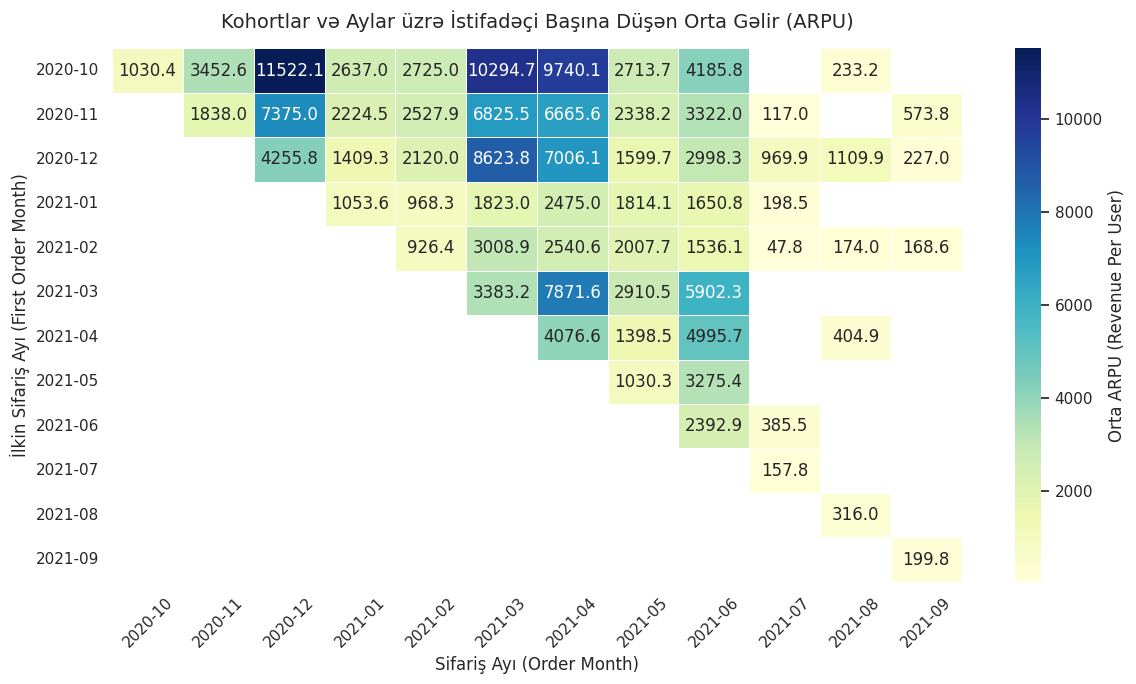

In [ ]:
# Pivot cədvəli dəyişənə mənimsəyirik
pivot_arpu = orders_grouped.pivot_table(
    index="first_order_month",
    columns="order_month",
    values="revenue_per_user",
    aggfunc="mean",
)

# Heatmap qrafiki
plt.figure(figsize=(12, 7))
sns.heatmap(
    pivot_arpu,
    annot=True,  # Xanadakı ARPU qiymətlərini göstərmək üçün
    fmt=".1f",  # Onluq kəsri 1 rəqəm dəqiqliklə formatlayırıq
    cmap="YlGnBu",  # Rəng palitrası
    linewidths=0.5,
    cbar_kws={"label": "Orta ARPU (Revenue Per User)"},
)

plt.title(
    "Kohortlar və Aylar üzrə İstifadəçi Başına Düşən Orta Gəlir (ARPU)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Sifariş Ayı (Order Month)", fontsize=12)
plt.ylabel("İlkin Sifariş Ayı (First Order Month)", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Erkən Kohortların Yüksək Dəyəri: 2020-ci ilin son rübündə (2020-10 və 2020-11) gələn istifadəçilər ən yüksək ARPU göstəricilərinə malikdir və platforma üçün uzunmüddətli əsas gəlir drayveridir.

Mövsümi və Kampaniya Sıçrayışları: Bütün kohortlarda 2020-12, 2021-03, 2021-04 və 2021-06 aylarında ARPU kəskin artır (məsələn, 2020-10 kohortu 2020-12 ayında 11,522.1 göstəricisi ilə zirvəyə çatır), bu da həmin aylardakı xüsusi satış və ya şəxsi kampaniya effektini göstərir.

Təkrar Satışların Effektivliyi: Köhnə istifadəçilər yalnız ilk ayda deyil, növbəti aylarda da (məsələn, 3-cü və 5-ci aylarda) yüksək ARPU nümayiş etdirərək təkrar alış-veriş meylinin güclü olduğunu təsdiqləyir.

Yeni Kohortlarda Keyfiyyət Düşüşü: 2021-ci ilin iyul ayından etibarən (2021-07, 2021-08 və 2021-09) sistemə daxil olan yeni istifadəçilərin ilkin ARPU göstəriciləri kəskin şəkildə (157.8 – 316.0 aralığına) geriləmişdir.

Müştəri Cəlbi və Retention Strategiyası: Təhlil göstərir ki, son aylarda cəlb olunan auditoriyanın alıcılıq qabiliyyəti aşağıdır; bu səbəbdən marketing kanallarının keyfiyyəti yenidən qiymətləndirilməli və gəlir gətirən köhnə müştəriləri saxlamaq üçün saxlanılma (retention) fəaliyyətləri gücləndirilməlidir.

### Task 11. Aylıq cohort lifetime
cohort_lifetime dəyişənini yaratmaq müştərilərin davranışını təqvimin spesifik aylarından (yanvar, fevral və s.) mücərrədləşdirib, hamısını bərabər start nöqtəsinə (0-cı aya) gətirərək müqayisə etmək üçün vacibdir.

In [ ]:
#Hər sifarişin customer-in ilk sifariş ayından neçə ay sonra baş verdiyini göstərən cohort_lifetime dəyişəni yaradaq İlk alış ayını lifetime 0 kimi qəbul edək

orders_grouped = orders_grouped.reset_index()
orders_grouped['cohort_lifetime'] = (orders_grouped['order_month']- orders_grouped['first_order_month'])
orders_grouped['cohort_lifetime']=orders_grouped['cohort_lifetime'].apply(lambda x: x.n)
orders_grouped

,first_order_month,order_month,revenue,uni_customer,revenue_per_user,cohort_lifetime
0,2020-10,2020-10,1.487875e+06,1444,1030.384427,0
1,2020-10,2020-11,6.801571e+05,197,3452.574009,1
2,2020-10,2020-12,3.203142e+06,278,11522.095031,2
3,2020-10,2021-01,3.322594e+05,126,2636.979183,3
4,2020-10,2021-02,2.316231e+05,85,2724.978188,4
5,2020-10,2021-03,1.358901e+06,132,10294.703451,5
6,2020-10,2021-04,1.061667e+06,109,9740.063450,6
7,2020-10,2021-05,1.682498e+05,62,2713.706484,7
8,2020-10,2021-06,1.004596e+05,24,4185.816917,8
9,2020-10,2021-08,2.332000e+02,1,233.200000,10


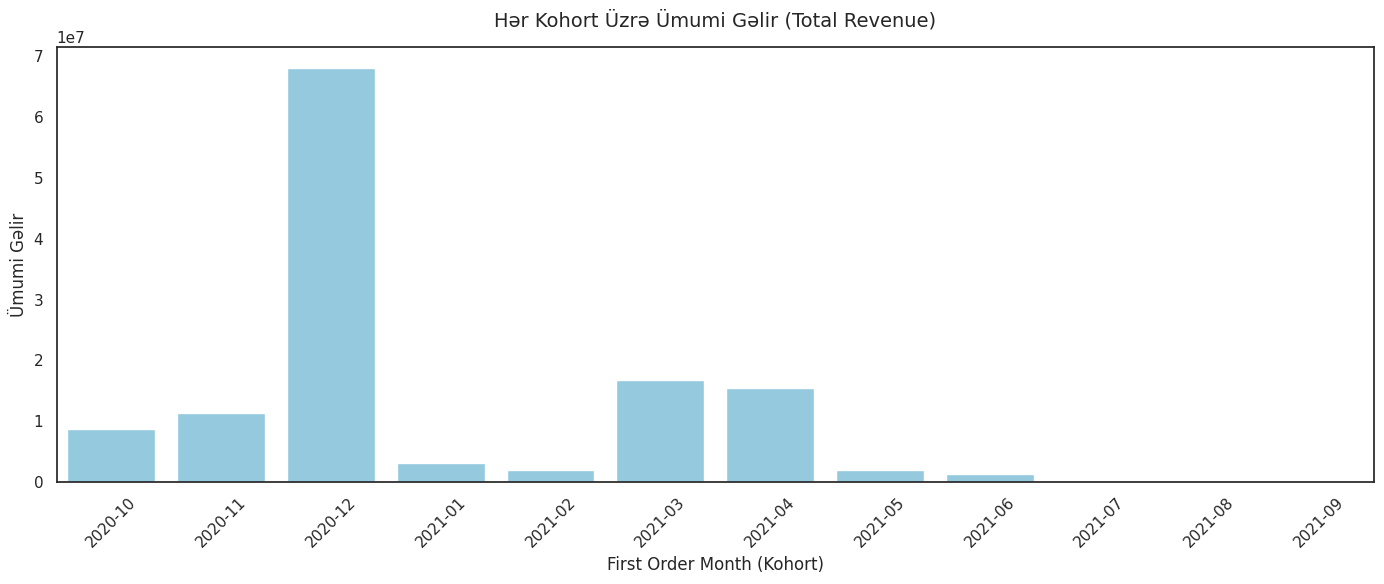

In [ ]:
# Kohortlar üzrə ümumi gəliri hesablamaq
cohort_revenue = (
    orders_grouped.groupby("first_order_month")["revenue"].sum().reset_index()
)

plt.figure(figsize=(14, 6))
sns.barplot(data=cohort_revenue, x="first_order_month", y="revenue", color="skyblue")

plt.title("Hər Kohort Üzrə Ümumi Gəlir (Total Revenue)", fontsize=14, pad=15)
plt.xlabel("First Order Month (Kohort)", fontsize=12)
plt.ylabel("Ümumi Gəlir", fontsize=12)
plt.xticks(rotation=45)  # Tarixlərin üst-üstə düşməməsi üçün bucaq altında yazırıq
plt.tight_layout()

plt.show()

2020-12 Kohortunda Anomal Sıçrayış (Pik Nöqtə): Qrafikdə ən çox diqqət çəkən məqam 2020-ci ilin Dekabr kohortudur. Bu kohortda ümumi gəlir en yuksek  həddə çataraq digər bütün aylardan dəfələrlə yüksək nəticə göstərib. Buna səbəb ilsonu (Yeni İl) kampaniyaları, kütləvi endirimlər və ya iri həcmli korporativ sifarişlər ola bilər.2021-ci
İlin Əvvəlində Müəyyən Canlılıq: 2021-ci ilin Mart və Aprel aylarında qoşulan kohortlar da digər adi aylarla müqayisədə daha yüksək gəlir gətirib.
Digər Aylarda Stabil və Aşağı Səviyyə:  2021-ci ilin İyul-Sentyabr aralığında qoşulan kohortların ümumi gəlir töhfəsi nisbətən aşağı və stabil  qalıb.
Biznes Insight (Tövsiyə): 2020-12 kohortunda hansı marketinq kanallarının və ya təkliflərin istifadə olunduğu araşdırılmalıdır. Həmin strategiyanı digər aylara da tətbiq edərək gəlir axınını tək bir aydan asılı olmaqdan xilas etmək lazımdır.

# Task 12. ARPU heatmap

Sətirlərdə aylıq cohort, sütunlarda `cohort_lifetime`, dəyər kimi ARPU olan pivot table yaradaq və heatmap ilə vizuallaşdıraq.

ARPU (Average Revenue Per User) — hər bir istifadəçidən və ya müştəridən əldə edilən orta gəlir göstəricisidir.Formula olaraq aşağıdakı kimi hesablanır:$$ARPU = \frac{\text{Ümumi Gəlir (Total Revenue)}}{\text{Aktiv Müştəri Sayı (Total Active Users)}}$$

Müştəri Dəyərinin Dinamikasını Anlamaq: Müştərilərin zaman keçdikcə platformada nə qədər pul xərclədiyini göstərir. Müştəri sayı azalsa bile, qalan sadiq müştərilərin daha çox xərcləyib-xərcləmədiyini (ARPU-nun artıb-artmadığını) müəyyən etməyə kömək edir.

In [ ]:
pivot = orders_grouped.pivot_table(
    index='first_order_month',
    columns='cohort_lifetime',
    values='revenue_per_user',
    aggfunc='mean',
)
pivot

cohort_lifetime,0,1,2,3,4,5,6,7,8,9,10
first_order_month,,,,,,,,,,,
2020-10,1030.384427,3452.574009,11522.095031,2636.979183,2724.978188,10294.703451,9740.063450,2713.706484,4185.816917,NaN,233.2
2020-11,1837.968325,7374.958003,2224.458538,2527.892314,6825.545797,6665.585770,2338.163167,3322.012054,117.000000,NaN,573.8
2020-12,4255.772939,1409.322951,2119.995244,8623.763975,7006.076809,1599.673220,2998.311748,969.900000,1109.915000,227.0,NaN
2021-01,1053.581193,968.332979,1822.987927,2474.969923,1814.091033,1650.835600,198.500000,NaN,NaN,NaN,NaN
2021-02,926.427042,3008.862019,2540.597829,2007.702000,1536.057300,47.800000,174.050000,168.600000,NaN,NaN,NaN
2021-03,3383.196040,7871.606230,2910.464734,5902.251708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-04,4076.632972,1398.458215,4995.734206,NaN,404.920000,NaN,NaN,NaN,NaN,NaN,NaN
2021-05,1030.271076,3275.389806,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-06,2392.941589,385.475000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


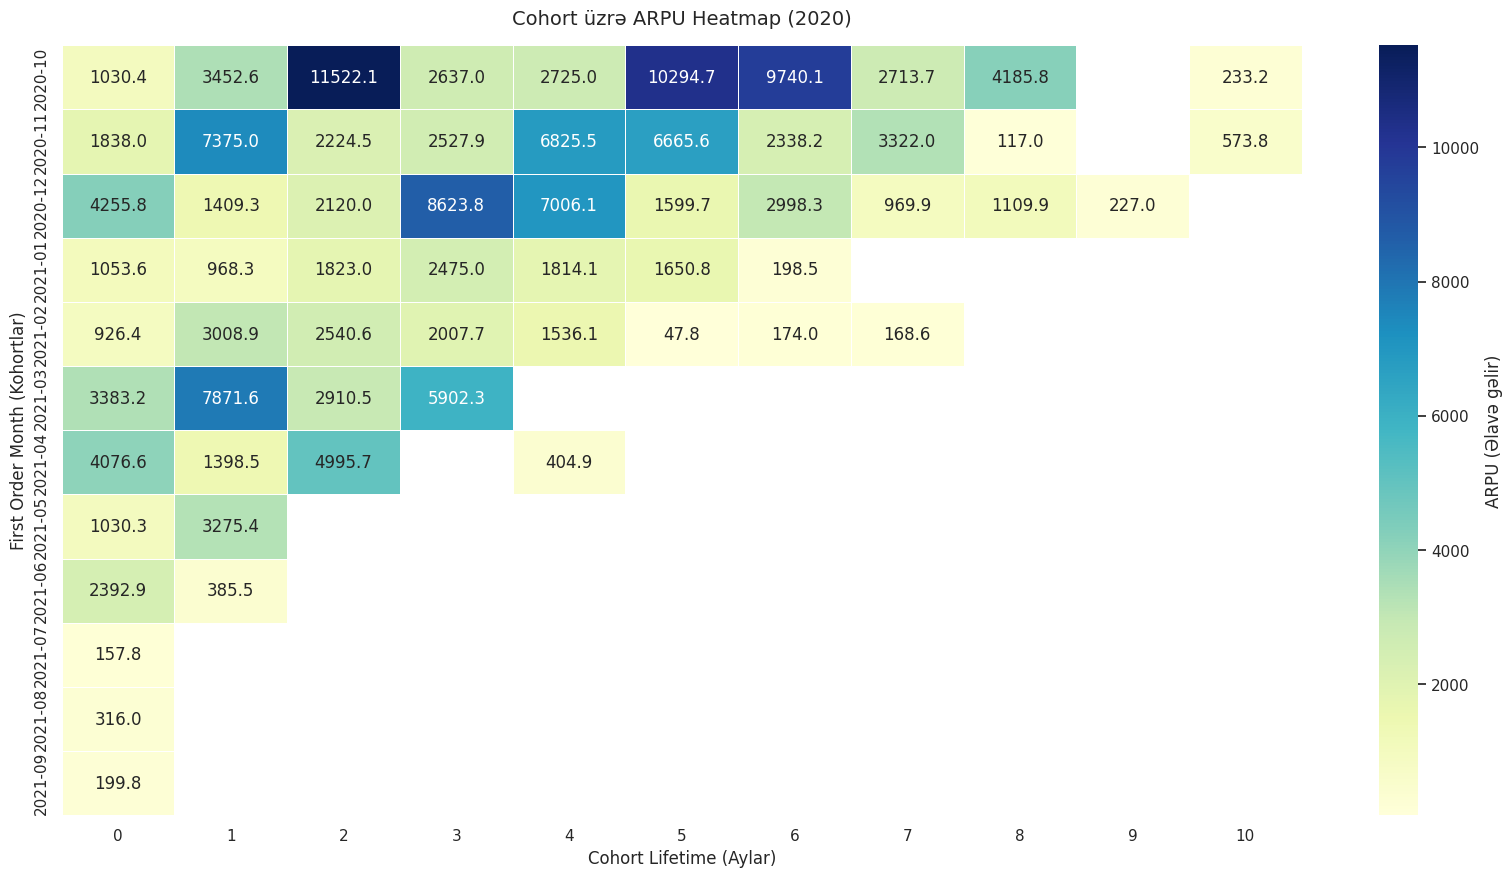

In [ ]:
# Qrafikin ölçüsünü təyin edirik
plt.figure(figsize=(20, 10))

# Seaborn ilə heatmap yaradırıq
sns.heatmap(
    pivot,
    annot=True,  # Xanaların içində qiymətlərin görünməsi üçün
    fmt=".1f",  # Ədədlərin nöqtədən sonra 1 rəqəmlə göstərilməsi üçün
    cmap="YlGnBu",  # Rəng palitrası (istəyə görə 'Blues', 'viridis' də ola bilər)
    linewidths=0.5,  # Xanalar arası xətt qalınlığı
    cbar_kws={"label": "ARPU (Əlavə gəlir)"},
)

# Başlıq və oxların adları
plt.title("Cohort üzrə ARPU Heatmap (2020)", fontsize=14, pad=15)
plt.xlabel("Cohort Lifetime (Aylar)", fontsize=12)
plt.ylabel("First Order Month (Kohortlar)", fontsize=12)

# Şəkli göstərmək
plt.show()

ARPU (Average Revenue Per User) dinamikası: Heatmap-də rəngin tündləşdiyi xanalar istifadəçi başına düşən orta gəlirin (ARPU) yüksək olduğunu, açıq rəngli və ya NaN olan xanalar isə gəlirin az və ya həmin ayda aktivliyin olmadığını göstərir.

Kohortların zamanla davranışı: Sol tərəfdən sağa doğru getdikcə (cohort_lifetime artdıqca) bəzi kohortlarda ARPU-nun kəskin artdığı müşahid olunur . Bu, müəyyən dövrdən sonra sadiq müştərilərin daha böyük məbləğdə alış-veriş etdiyini göstərir.

Üçbucaq forması (Data itkisi): Qrafikin sağ aşağı küncünə doğru NaN (boş) xanaların artması təbii hallardır, çünki daha sonrakı aylarda qoşulan kohortların (məsələn, 2021-09) hələ uzunmüddətli yaşam dövrü (lifetime) formalaşmayıb.

## 3. Həftəlik retention analysis

Həftəlik Retention Rate (Müştərini Saxlama Dərəcəsi) belirli bir həftədə xidmətdən/məhsuldan ilk dəfə istifadə etməyə başlayan müştərilərin (kohortun) sonrakı həftələrdə nə qədərinin geri qayıdıb təkrar aktivlik/alış-veriş göstərdiyini faizlə ölçən analitik göstəricidir.Sadə desək: "Ötən həftələrdə gələn istifadəçilərin bu həftə neçə faizi bizimlə qaldı?" sualına cavab verir.Düsturu$N$-ci həftə üçün Retention Rate aşağıdakı kimi hesablanır:$$\text{Retention Rate (\%)} = \left( \frac{\text{Həftə } N\text{-də aktiv olan kohort müştərilərinin sayı}}{\text{Kohortun başlanğıcındakı (Həftə 0) ümumi müştəri sayı}} \right) \times 100$$

### Task 13. Həftəlik period-lar

Hər sifariş üçün sifarişin baş verdiyi həftənin başlanğıc tarixini, hər customer üçün isə ilk alış həftəsinin başlanğıc tarixini hesablayaq.


In [ ]:
orders = orders.reset_index(drop=True)
orders


,cust_id,order_date,order_id,revenue,first_order,first_order_month,order_month
0,60124,2020-10-01,100354680,1349.10,2020-10-01,2020-10,2020-10
1,60124,2020-10-01,100354680,719.10,2020-10-01,2020-10,2020-10
2,42485,2020-12-24,100403536,662.48,2020-12-24,2020-12,2020-12
3,42485,2020-12-24,100403536,820.30,2020-12-24,2020-12,2020-12
4,42485,2020-12-24,100403536,181.48,2020-12-24,2020-12,2020-12
...,...,...,...,...,...,...,...
85730,113791,2021-09-02,100554480,58.00,2021-09-02,2021-09,2021-09
85731,113791,2021-09-02,100554480,69.80,2021-09-02,2021-09,2021-09
85732,113791,2021-09-02,100554480,27.00,2021-09-02,2021-09,2021-09
85733,113791,2021-09-02,100554480,18.00,2021-09-02,2021-09,2021-09


In [ ]:
orders.drop(columns=["first_order_month", "order_month"], axis=1, inplace=True)

In [ ]:
orders['order_date'].dt.weekday

,order_date
0,3
1,3
2,3
3,3
4,3
...,...
85730,3
85731,3
85732,3
85733,3


 Pandas günləri belə kodlaşdırır

 0  Bazar ertəsi (Monday)

 1  Çərşənbə axşamı (Tuesday)

 2  Çərşənbə (Wednesday)

 3  Cümə axşamı (Thursday)

 4  Cümə (Friday)

 5  Şənbə (Saturday)

 6  Bazar (Sunday)

In [ ]:
orders['week_of_orders'] = (orders['order_date']- pd.to_timedelta(orders['order_date'].dt.weekday, unit='d'))
orders

,cust_id,order_date,order_id,revenue,first_order,week_of_orders
0,60124,2020-10-01,100354680,1349.10,2020-10-01,2020-09-28
1,60124,2020-10-01,100354680,719.10,2020-10-01,2020-09-28
2,42485,2020-12-24,100403536,662.48,2020-12-24,2020-12-21
3,42485,2020-12-24,100403536,820.30,2020-12-24,2020-12-21
4,42485,2020-12-24,100403536,181.48,2020-12-24,2020-12-21
...,...,...,...,...,...,...
85730,113791,2021-09-02,100554480,58.00,2021-09-02,2021-08-30
85731,113791,2021-09-02,100554480,69.80,2021-09-02,2021-08-30
85732,113791,2021-09-02,100554480,27.00,2021-09-02,2021-08-30
85733,113791,2021-09-02,100554480,18.00,2021-09-02,2021-08-30


Bu kod hər bir sifarişin baş verdiyi həftənin ilk gününü (Bazar ertəsini) hesablayır və weekly_orders sütununa yazır.

Qısa desək, tarixləri həftənin başlanğıcına yuvarlaqlaşdırır.

In [ ]:
orders['first_orders_week'] = (orders['first_order']- pd.to_timedelta(orders['first_order'].dt.weekday, unit='d'))
orders

,cust_id,order_date,order_id,revenue,first_order,week_of_orders,first_orders_week
0,60124,2020-10-01,100354680,1349.10,2020-10-01,2020-09-28,2020-09-28
1,60124,2020-10-01,100354680,719.10,2020-10-01,2020-09-28,2020-09-28
2,42485,2020-12-24,100403536,662.48,2020-12-24,2020-12-21,2020-12-21
3,42485,2020-12-24,100403536,820.30,2020-12-24,2020-12-21,2020-12-21
4,42485,2020-12-24,100403536,181.48,2020-12-24,2020-12-21,2020-12-21
...,...,...,...,...,...,...,...
85730,113791,2021-09-02,100554480,58.00,2021-09-02,2021-08-30,2021-08-30
85731,113791,2021-09-02,100554480,69.80,2021-09-02,2021-08-30,2021-08-30
85732,113791,2021-09-02,100554480,27.00,2021-09-02,2021-08-30,2021-08-30
85733,113791,2021-09-02,100554480,18.00,2021-09-02,2021-08-30,2021-08-30


Bu kod müştərinin ən birinci sifariş verdiyi tarixin (first_order) aid olduğu həftənin Bazar ertəsini tapır və first_weekly_orders sütununa yazır.

Yəni:

week_of_orders: Cari sifarişin olduğu həftənin başlanğıcıdır (Bazar ertəsi).

first_orders_week: Müştərinin sistemdə qeydiyyatdan keçdiyi / ilk dəfə mal aldığı həftənin başlanğıcıdır (Kohortun adı).



### Task 14. Həftəlik cohort lifetime

Hər sifarişin customer-in ilk alış həftəsindən neçə həftə sonra baş verdiyini göstərən həftəlik `cohort_lifetime` yaradaq

In [ ]:
orders['cohort_lifetime'] = (orders['week_of_orders'] - orders['first_orders_week'])
orders.sample(5)

,cust_id,order_date,order_id,revenue,first_order,week_of_orders,first_orders_week,cohort_lifetime
8862,61519,2020-10-26,100359872,516.60,2020-10-26,2020-10-26,2020-10-26,0 days
49200,76661,2020-12-27,100412436,3529.44,2020-12-27,2020-12-21,2020-12-21,0 days
43200,73756,2020-12-24,100403152,139.80,2020-12-24,2020-12-21,2020-12-21,0 days
42033,73291,2020-12-23,100401526,1658.70,2020-12-23,2020-12-21,2020-12-21,0 days
49722,76790,2020-12-27,100412959,89.60,2020-12-27,2020-12-21,2020-12-21,0 days


cohort life_time i gunlerle yox heftelerle ifade edek

In [ ]:
orders['cohort_lifetime'] = orders['cohort_lifetime'] / np.timedelta64(1, 'W')
orders['cohort_lifetime'] = orders['cohort_lifetime'].astype(int)
orders.sample(5)

,cust_id,order_date,order_id,revenue,first_order,week_of_orders,first_orders_week,cohort_lifetime
53392,78526,2020-12-27,100419025,7479.00,2020-12-27,2020-12-21,2020-12-21,0
55794,79945,2020-12-28,100423468,242.22,2020-12-28,2020-12-28,2020-12-28,0
81154,97123,2021-04-21,100485342,1559.00,2021-04-21,2021-04-19,2021-04-19,0
28620,67900,2020-12-20,100384039,5467.30,2020-12-20,2020-12-14,2020-12-14,0
67394,86649,2021-05-07,100510001,51.80,2021-05-07,2021-05-03,2021-05-03,0


#Həftəlik active customer-lər

Datanı ilk alış həftəsi və həftəlik `cohort_lifetime` üzrə qruplaşdıraraq hər qrup üçün unique active customer sayını hesablayaq.

In [ ]:
cohorts = (orders.groupby(['first_orders_week', 'cohort_lifetime']).agg({'cust_id': 'nunique'}).reset_index())
cohorts=cohorts.rename(columns={'cust_id':'customer_count'})
cohorts

,first_orders_week,cohort_lifetime,customer_count
0,2020-09-28,0,323
1,2020-09-28,1,13
2,2020-09-28,2,13
3,2020-09-28,3,12
4,2020-09-28,4,5
...,...,...,...
714,2021-08-02,0,6
715,2021-08-09,0,5
716,2021-08-16,0,2
717,2021-08-23,0,3


#İlkin kohort ölçüsü
Retention Rate hesablamaq üçün əvvəlcə kohortdakı ilkin istifadəçi sayını əldə etməli və bunu sonrakı hər həftə üçün istifadəçi sayına bölməliyik.

Kohortdakı ilkin istifadəçi sayını 0-cı həftəyə baxaraq tapaq:




In [ ]:
#Hər həftəlik cohort üçün lifetime 0-dakı customer sayını müəyyən edək və bu məlumatı həftəlik cohort cədvəlinə əlavə edək

cohort0 = cohorts[cohorts['cohort_lifetime'] == 0][['first_orders_week', 'customer_count']]
cohort0.head()

,first_orders_week,customer_count
0,2020-09-28,323
37,2020-10-05,365
73,2020-10-12,265
109,2020-10-19,309
141,2020-10-26,186


In [ ]:
cohort0 = cohort0.rename( columns={'customer_count': '0cohortcustomer'})
cohort0.head()

,first_orders_week,0cohortcustomer
0,2020-09-28,323
37,2020-10-05,365
73,2020-10-12,265
109,2020-10-19,309
141,2020-10-26,186


cohort cedveli ile cohort 0 cedvelini birləşdirək

In [ ]:
cohorts = cohorts.merge(cohort0, on='first_orders_week')
cohorts

,first_orders_week,cohort_lifetime,customer_count,0cohortcustomer
0,2020-09-28,0,323,323
1,2020-09-28,1,13,323
2,2020-09-28,2,13,323
3,2020-09-28,3,12,323
4,2020-09-28,4,5,323
...,...,...,...,...
714,2021-08-02,0,6,6
715,2021-08-09,0,5,5
716,2021-08-16,0,2,2
717,2021-08-23,0,3,3


# Retention rate

Hər cohort və həftəlik lifetime üçün retention rate hesablayaq.

In [ ]:
cohorts['retention_rate'] = (cohorts['customer_count'] / cohorts['0cohortcustomer'])
cohorts

,first_orders_week,cohort_lifetime,customer_count,0cohortcustomer,retention_rate
0,2020-09-28,0,323,323,1.000000
1,2020-09-28,1,13,323,0.040248
2,2020-09-28,2,13,323,0.040248
3,2020-09-28,3,12,323,0.037152
4,2020-09-28,4,5,323,0.015480
...,...,...,...,...,...
714,2021-08-02,0,6,6,1.000000
715,2021-08-09,0,5,5,1.000000
716,2021-08-16,0,2,2,1.000000
717,2021-08-23,0,3,3,1.000000


#Retention matrix və heatmap

Həftəlik retention nəticəsini pivot table formasına çevirək və faiz formatında heatmap hazırlayaq. Customer retention-un ilk həftələrdə necə dəyişdiyini şərh edək.

In [ ]:
pivotretention = cohorts.pivot_table(index='first_orders_week',columns='cohort_lifetime', values='retention_rate',  aggfunc='mean')
pivotretention

cohort_lifetime,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,39,41,42,43
first_orders_week,,,,,,,,,,,,,,,,,,,,,
2020-09-28,1.0,0.040248,0.040248,0.037152,0.015480,0.040248,0.061920,0.043344,0.043344,0.030960,...,0.015480,0.015480,0.009288,0.006192,0.015480,0.006192,NaN,NaN,NaN,NaN
2020-10-05,1.0,0.057534,0.043836,0.021918,0.046575,0.032877,0.038356,0.046575,0.027397,0.030137,...,0.010959,0.027397,0.019178,0.010959,0.005479,NaN,NaN,NaN,NaN,NaN
2020-10-12,1.0,0.090566,0.045283,0.079245,0.067925,0.052830,0.060377,0.056604,0.090566,0.128302,...,0.026415,0.011321,0.015094,0.007547,NaN,NaN,NaN,NaN,0.003774,NaN
2020-10-19,1.0,0.032362,0.038835,0.045307,0.022654,0.016181,0.032362,0.038835,0.077670,0.093851,...,0.009709,0.009709,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-10-26,1.0,0.080645,0.075269,0.064516,0.086022,0.069892,0.053763,0.107527,0.129032,0.080645,...,0.010753,0.005376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-11-02,1.0,0.103261,0.054348,0.065217,0.062500,0.048913,0.160326,0.171196,0.076087,0.057065,...,0.002717,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-11-09,1.0,0.049462,0.033333,0.032258,0.043011,0.102151,0.135484,0.051613,0.034409,0.025806,...,NaN,NaN,0.001075,0.001075,NaN,NaN,NaN,NaN,NaN,0.001075
2020-11-16,1.0,0.037162,0.030405,0.035473,0.072635,0.079392,0.048986,0.016892,0.021959,0.015203,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001689,NaN
2020-11-23,1.0,0.050761,0.040609,0.073604,0.116751,0.048223,0.038071,0.032995,0.025381,0.005076,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


NaN = 0% retention deyil.
Xüsusilə son cohort-larda gələcək həftələrdə NaN olması “müştəri qayıtmayıb” demək deyil. Sadəcə həmin cohort-un o qədər uzun müşahidə müddəti yoxdur.
Retention nəticələri çox aşağıdır və bu, əsas biznes insight-dır.
Məsələn ilk cohort-lardan biri üçün Week 1 retention 4.02% göstərilir. Bu, ilk alışdan sonrakı həftədə geri qayıdan müştərilərin çox az olduğunu göstərir. bu o deməkdir ki, müşahidə olunan təkrar alış saxlama səviyyəsi aşağıdır

In [ ]:
import pandas as pd
import plotly.express as px


pivotretention.index = pd.to_datetime(pivotretention.index)

pivotretention.index = pivotretention.index.strftime('%Y-%m-%d')
pivotretention.columns = pivotretention.columns.astype(str)

fig = px.imshow(
   pivotretention.values,
    x=pivotretention.columns,
    y=pivotretention.index,
    labels={
        "x": "Cohort Period (Lifetime)",
        "y": "First Buy Week",
        "color": "Retention"
    },
    color_continuous_scale="Reds",
    text_auto=".1%",
    aspect="auto"
)


fig.update_yaxes(type='category')

fig.update_layout(
    title="Cohorts: User Retention",
    width=2000,
    height=950
)
fig.show()

Kəskin İlkin Düşüş (Ilk Həftə Düşüşü): İlk həftədən (Lifetime 1) etibarən bütün kohortlar üzrə Saxlanma Dərəcəsi (Retention) kəskin şəkildə 3% – 10% aralığına düşür. Bu, istifadəçilərin böyük əksəriyyətinin ilkin alışdan dərhal sonra platformanı tərk etdiyini gösterir.

Müstəsna Kohortlar (Uğurlu Kampaniyalar/Aksiyalar): 2020-12-07 (18.4%) və 2020-12-14 (19.6%) kohortlarında 1-ci həftə retention nisbətən yüksək olub. Dekabr ayındakı bu aktivlik bayram öncəsi aksiyaların və ya xüsusi kampaniyaların nəticəsi ola bilər.

Uzunmüddətli Sabitləşmə: Dövriyyədə qalan azsaylı istifadəçi kütləsi (həftələr keçdikcə 0.5% – 3% arası) uzun müddət aktivliyini saxlayır, yəni sadiq istifadəçi bazası olduqca kiçikdir.

Tövsiyə: Əsas diqqəti istifadəçilərin onboarding (platformaya alışma) prosesinə və 1-ci həftədə onları yenidən platformaya qaytaracaq (retargeting, push notification, xüsusi endirimlər) mexanizmlərə yönəltmək lazımdır.

#Churn rate

Retention nəticəsindən istifadə edərək cumulative churn rate hesablayaq, matrix yaradaq və heatmap ilə göstərək.


In [ ]:
cohorts['churn_rate'] = 1 - cohorts['retention_rate']
cohorts



,first_orders_week,cohort_lifetime,customer_count,0cohortcustomer,retention_rate,churn_rate
0,2020-09-28,0,323,323,1.000000,0.000000
1,2020-09-28,1,13,323,0.040248,0.959752
2,2020-09-28,2,13,323,0.040248,0.959752
3,2020-09-28,3,12,323,0.037152,0.962848
4,2020-09-28,4,5,323,0.015480,0.984520
...,...,...,...,...,...,...
714,2021-08-02,0,6,6,1.000000,0.000000
715,2021-08-09,0,5,5,1.000000,0.000000
716,2021-08-16,0,2,2,1.000000,0.000000
717,2021-08-23,0,3,3,1.000000,0.000000


In [ ]:
churn_pivot = cohorts.pivot_table(
    index='first_orders_week',
    columns='cohort_lifetime',
    values='churn_rate',
    aggfunc='sum',
)
churn_pivot.index = pd.to_datetime(churn_pivot.index).strftime('%Y-%m-%d')
sns.set(style='white')
plt.figure(figsize=(45, 25),dpi=300)
plt.title('Cohorts: Churn Rate')
sns.heatmap(churn_pivot, annot=True, fmt='.0%', linewidths=1, linecolor='gray')

<Axes: title={'center': 'Cohorts: Churn Rate'}, xlabel='cohort_lifetime', ylabel='first_orders_week'>

İlkin mərhələdə kəskin itki: 1-ci həftədən (cohort_lifetime = 1) etibarən bütün kohortlar üzrə müştəri itkisi kəskin şəkildə 80% – 97% aralığına çatır.

Tədricən 100%-ə çatması: Zaman keçdikcə Churn Rate tədricən artaraq 98-100%-ə yaxınlaşır; bu da Retention-un tam sıfırlanması ilə üst-üstə düşür.

Müstəsna Kohortlar: 2020-12-07 (82%) və 2020-12-14 (80%) kohortlarında 1-ci həftənin itkisi nisbətən aşağı olub, yəni həmin dövrdə gələn istifadəçilər platformada daha yaxşı saxlanıb.

Metodoloji Düzgünlük: Kod düzəldildiyi üçün artıq heatmap-də mənfi və ya 100%-dən böyük anomaliyalar yoxdur; göstəricilər 0% ilə 100% aralığında tam məntiqi görünür.

#Nəticə (Conclusion)

İlkin Dövriyyədə Yüksək Müştəri İtkisi: İstifadəçilərin 90–97%-i ilk həftədən (cohort_lifetime = 1) sonra platformanı tərk edir. Bu, əsas problemin müştəri cəlb etməkdə (acquisition) deyil, ilkin aktivləşdirmə və platformada saxlama (activation/retention) mərhələsində olduğunu göstərir.

Sadiq Müştəri Bazası Kiçikdir: Həftələr keçdikcə Retention Rate 0.5% – 3% arasında sabitləşir, Cumulative Churn isə 98–100%-ə yaxınlaşır. Platformada yalnız çox kiçik bir nüvə istifadəçi kütləsi uzunmüddətli qalır.

Mövsümi Kampaniyaların Yüksək Effektivliyi: 2020-ci ilin dekabr kohortlarında (xüsusilə 07.12 və 14.12 tarixlərində) 1-ci həftə Retention göstəricisi digər dövrlərə nəzərən daha yüksək (18–19.6%) olub. Bu, bayram öncəsi təkliflərin və xüsusi kampaniyaların müştəri saxlanmasına müsbət təsir etdiyini sübut edir.

#Tövsiyələr (Recommendations)

Onboarding (İlkin Təcrübə) Prosesini Optimallaşdırmaq: İstifadəçinin platformaya daxil olduğu ilk 7 gün ərzində məhsulun dəyərini tez anlaması (Aha moment) üçün istiqamətləndirici addımlar və ilkin istifadəçi təcrübəsi yenidən işlənməlidir.

1-ci Həftə Xüsusi Saxlama Mexanizmləri: İlk həftədə istifadəçiləri geri qaytarmaq üçün hədəflənmiş push notification-lar, e-mail xatırlatmaları və ikinci sifariş/əməliyyat üçün xüsusi endirim bonusları tətbiq edilməlidir.

Uğurlu Kampaniyaların Analizi və Təkrarı: Dekabr ayındakı kohortların yüksək retention səbəbləri (təklif olunan endirimlər, reklam kanalları və ya məhsul çeşidi) detallı təhlil edilməli və bu strategiya digər aylara da inteqrasiya olunmalıdır.

Kohort Təhlilini Seqmentlərə Ayırmaq: Müştəriləri ümumi şəkildə deyil, gəldikləri trafiki (organic, paid ad), cihaz növünü və ya ilk alıcılıq kateqoriyalarını nəzərə alaraq seqmentləşdirilmiş kohortlarla izləmək daha dəqiq strategiya qurmağa kömək edəcək.

<!-- Cavabınızı burada yazın. -->